# Bayesian Classification
Henry Arnold, Cole Clodgo, Bao Lam, Nguyen Nguyen, Ryan Vo

In this project we compute Bayesian classifications for the MNIST data set. This data set contains images of handdrawn digits. We choose the digits 7 and 9 for classification. We try two different likelihood functions, a normal distribution and a Bernoulli distribution. We first compute the classifications by hand, and then use the sklearn package to also compute the classifications.

In [25]:
# module imports
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay

## Getting the Data
We get the mnist dataset from keras already split into training and testing data. X_train and X_test contain the training and testing images as numpy arrays of pixels. Y_train and Y_test contain the digit labels for each image in X_train and X_test. We filter down to just two digits for our binary classification, choosing 7 and 9. To get the image data into a more workable form, we flatten them from 28x28 2D arrays down to a 1D array of 784 pixels, and convert the pixel values to floats for later calculations. The images remain grayscale rather than being converted to black and white.

In [26]:
# get the data
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# Choose two digits
digit1 = 7
digit2 = 9

# Keeping only the selected digits
train_mask = (Y_train == digit1) | (Y_train == digit2)
test_mask = (Y_test == digit1) | (Y_test == digit2)

X_train = X_train[train_mask]
Y_train = Y_train[train_mask]

X_test = X_test[test_mask]
Y_test = Y_test[test_mask]

# Flattening images from 28x28 to 784 pixels
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Convert to float for later calculations
X_train = X_train.astype(float)
X_test = X_test.astype(float)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (12214, 784)
Testing samples: (2037, 784)


## Assumption: Normal Distribution

### Hand-Coded Normal Distribution

#### 1. Train on Digit 7 and 9 (Mean, Variance, and Standard Deviation Calculation)

In [27]:
# Mean
def mean(data_set):
    mean_array = np.mean(data_set, axis=0)
    return mean_array


# Standard deviation
def standard_deviation(data_set):
    std_array = np.std(data_set, axis=0)
    return std_array

# Smooth variance to keep them from being zero in denominator
def smooth_variance(standard_deviation):
    variance = standard_deviation**2
    constant = (10**-9) * np.max(variance)
    return variance + constant


In [28]:
# Execution

## Separate training images by digit
X_train_7 = X_train[Y_train == 7]
X_train_9 = X_train[Y_train == 9]

## Calculate mean arrays
mean_7 = mean(X_train_7)
mean_9 = mean(X_train_9)

## Calculate standard deviation arrays
sd_7 = standard_deviation(X_train_7)
sd_9 = standard_deviation(X_train_9)

## Calculate the smooth variance arrays
variance_7 = smooth_variance(sd_7)
variance_9 = smooth_variance(sd_9)

#### 2. Prior Calculation

In [29]:
# Prior function
def prior(label_set, chosen_class, other_class):
    chosen_count = np.sum(label_set == chosen_class)
    other_count = np.sum(label_set == other_class)
    return chosen_count / (chosen_count + other_count)

In [30]:
# Execution

## Calculate prior for 7
prior_7 = prior(Y_train, 7, 9)

## Calculate prior for 9
prior_9 = prior(Y_train, 9, 7)

#### 3. Gaussian Likelihood

In [31]:
# Likelihood function
# Taking the log of the Gaussian likelihood function give us the formula for log likelihood
# Use that formula to derive the function

def log_likelihood(data_set, mean_array, variance_array):
    log_density = (-0.5 * np.log(2 * np.pi * variance_array) - ((data_set - mean_array)**2 / (2 * variance_array)))
    log_likelihood = np.sum(log_density, axis=1)

    return log_likelihood

In [32]:
# Execution
log_likelihood_7 = log_likelihood(X_test, mean_7, variance_7)
log_likelihood_9 = log_likelihood(X_test, mean_9, variance_9)


#### 4. Discriminant Function

In [33]:
# Calculating gi(x)

g_7 = log_likelihood_7 + np.log(prior_7)
g_9 = log_likelihood_9 + np.log(prior_9)

#### 5. Comparison & Prediction

In [34]:
# Predict 7 if g_7 larger than g_9
Y_pred = np.where(g_7 > g_9, 7, 9)

#### 6. Model Evaluation

In [35]:
# Accuracy
accuracy = accuracy_score(Y_test, Y_pred)

# F1 score (digit 9 as positive class)
f1 = f1_score(Y_test, Y_pred, pos_label=9)

# Confusion matrix
cm = confusion_matrix(Y_test, Y_pred, labels=[7, 9])

print("Accuracy:", accuracy)
print("F1 score:", f1)
print("Confusion matrix:\n", cm)

Accuracy: 0.6401570937653411
F1 score: 0.7294204503506829
Confusion matrix:
 [[316 712]
 [ 21 988]]


When assuming a normally distributed likelihood function and calculating the Bayesian classifications by hand, we achieve an accuracy of 0.64 and an F1 score of 0.73.

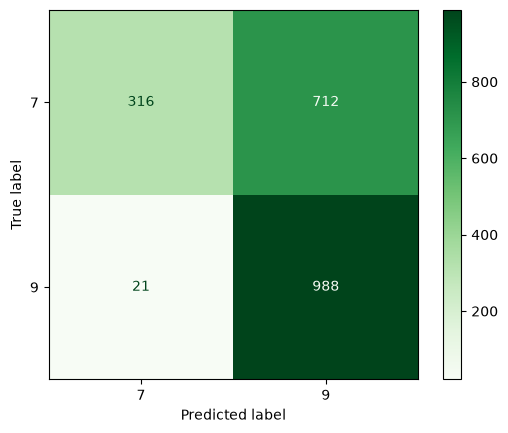

In [36]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[7, 9]
).plot(cmap="Greens")

plt.show()

### Scikit-Learn Gaussian Distribution

#### 1. Fit the Model

In [37]:
# Initialize model
clf = GaussianNB()

# Fit the model using training data
clf.fit(X_train, Y_train)

# Predict test data
Y_pred_sklearn = clf.predict(X_test)

#### 2. Evaluate the Model

In [38]:
# Accuracy
accuracy_sklearn = accuracy_score(Y_test, Y_pred_sklearn)

# F1 score (digit 9 as positive class)
f1_sklearn = f1_score(Y_test, Y_pred_sklearn, pos_label=9)

# Confusion matrix
cm_sklearn = confusion_matrix(Y_test, Y_pred_sklearn, labels=[7, 9])

print("Accuracy:", accuracy_sklearn)
print("F1 Score:", f1_sklearn)
print("Confusion Matrix:\n", cm_sklearn)

Accuracy: 0.6406480117820325
F1 Score: 0.7296898079763663
Confusion Matrix:
 [[317 711]
 [ 21 988]]


When assuming a normally distributed likelihood function and using the sklearn GaussianNB classifier to compute the Bayesian classifications, we achieve an accuracy of 0.64 and an F1 score of 0.73.

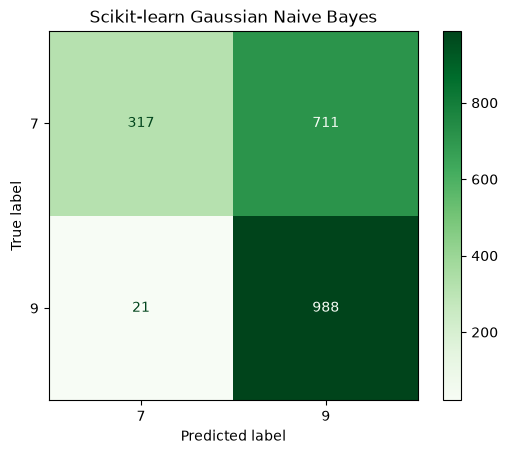

In [39]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_sklearn,
    display_labels=[7, 9]
).plot(cmap="Greens")

plt.title("Scikit-learn Gaussian Naive Bayes")
plt.show()

## Normal Likelihood Analysis
We compute the confusion matrices made by doing Bayesian classification where we assume the likelihood function is normally distributed by hand, as well as by using the sklearn built-in GaussianNB classifier. The two confusion matrices are almost identical. Our hand-coded model labels one additional image of a 7 as a 9, while sklearn correctly labels that image as a 7. Other than that one image, the two methods produce the same predictions. The slight difference may be due to the way variance smoothing is calculated.

Both models have an accuracy of about 0.64, meaning they correctly identify about 64% of the test images. They also both have an F1 score of about 0.73 for digit 9. The F1 score combines precision and recall, but that does not mean those two values are equal. Looking at the confusion matrices, the models identify almost every 9 correctly, but also mistake many 7s for 9s. This gives us high recall for 9 but much lower precision. The Gaussian approach therefore favors predicting 9 and does not separate these two digits very well.

## Assumption: Bernoulli distribution

### Hand-coded Bernoulli distribution

#### 1. Training the model

In [16]:
## Binarize (1 = pixel below 127, following the assignment)
X_train_bin = (X_train < 127).astype(int)
X_test_bin  = (X_test  < 127).astype(int)

## Separate binarized training images by digit
X_train_bin_7 = X_train_bin[Y_train == digit1]
X_train_bin_9 = X_train_bin[Y_train == digit2]

##### Calculate priors

In [17]:
prior_7 = prior(Y_train, digit1, digit2)
prior_9 = prior(Y_train, digit2, digit1)

##### Laplace smoothing function: Compute Θi,j 

In [18]:
def laplace_theta(X_class):
    return (X_class.sum(axis=0) + 1) / (X_class.shape[0] + 2)

theta_7 = laplace_theta(X_train_bin_7)
theta_9 = laplace_theta(X_train_bin_9)

##### Discriminant function g_i(x) for every test image

In [19]:
def bernoulli_discriminant(X, prior, theta):
    return np.log(prior) + X @ np.log(theta) + (1 - X) @ np.log(1 - theta)
    
g_7 = bernoulli_discriminant(X_test_bin, prior_7, theta_7)
g_9 = bernoulli_discriminant(X_test_bin, prior_9, theta_9)

#### 2. Testing the model

In [20]:
# Predict: the class with the larger score wins
pred = np.where(g_9 > g_7, digit2, digit1)

#### 3. Evaluating the model

[[915 113]
 [ 36 973]]
Accuracy: 0.9268532155130094
F1: 0.9288782816229116


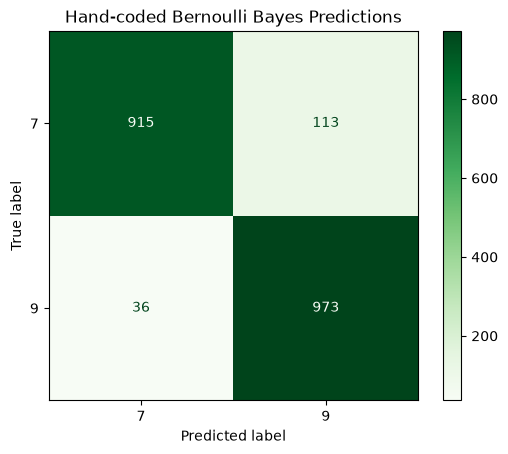

In [21]:
print(confusion_matrix(Y_test, pred, labels=[digit1, digit2]))
print("Accuracy:", accuracy_score(Y_test, pred))
print("F1:", f1_score(Y_test, pred, pos_label=digit2))

ConfusionMatrixDisplay.from_predictions(Y_test, pred, labels=[digit1, digit2], cmap="Greens", values_format="d")
plt.title("Hand-coded Bernoulli Bayes Predictions")
plt.show()

### Scikit-Learn Bernoulli distribution

#### 1. Training the model

In [22]:
clf = BernoulliNB(alpha=1.0, binarize=None).fit(X_train_bin, Y_train)

#### 2. Testing the model

In [23]:
pred_sk = clf.predict(X_test_bin)

#### 3. Evaluating the model

[[915 113]
 [ 36 973]]
Accuracy: 0.9268532155130094
F1: 0.9288782816229116


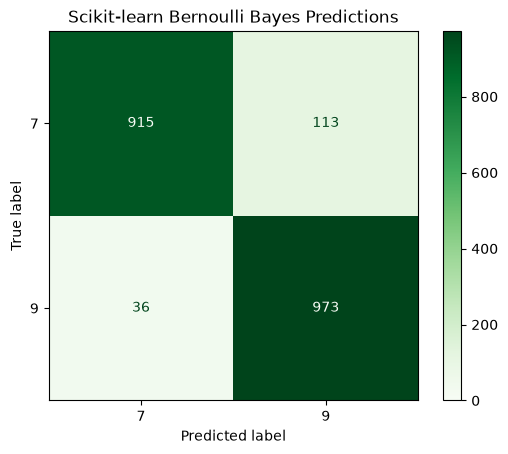

In [24]:
cm_sk = confusion_matrix(Y_test, pred_sk, labels=[digit1, digit2])
print(cm_sk)
print("Accuracy:", accuracy_score(Y_test, pred_sk))
print("F1:", f1_score(Y_test, pred_sk, pos_label=digit2))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_sk, display_labels=[digit1, digit2])
disp.plot(cmap="Greens", values_format="d", im_kw={"vmin": 0})
plt.title("Scikit-learn Bernoulli Bayes Predictions")
plt.show()

## Bernoulli Likelihood Analysis
In this version, we assumed a Bernoulli distribution for the likelihood function. Unlike the Gaussian model, which used grayscale values from 0 to 255, the Bernoulli model needs each pixel to be either 0 or 1. Following the threshold suggested in the assignment, we set pixels below 127 to 1 and all other pixels to 0. We then used Laplace smoothing to estimate the probability that each pixel is 1 for each digit. The formula `(count + 1) / (n + 2)` keeps those probabilities from being exactly 0 or 1.

We used the same binary training and testing data for both implementations. In sklearn, `alpha=1.0` applies the same smoothing, and `binarize=None` means it uses our already-binarized pixels rather than converting them a second time. Compare the two confusion matrices, accuracy scores, and F1 scores after running both sections. They should agree because the two implementations use the same probabilities and class priors.

The confusion matrices also let us look at which digits get mixed up. We use 9 as the positive class, so false positives are 7s predicted as 9s and false negatives are 9s predicted as 7s. Comparing this section with the Gaussian results tells us whether the binary pixel model does a better job separating these digits.